In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import matplotlib.pyplot as plt

In [2]:
df_model = pd.read_csv(
    "../data_processed/eda_main_49.csv"
)

print("지역 수:", len(df_model))
print("결측치:", df_model.isna().sum().sum())

display(df_model.head())

지역 수: 49
결측치: 0


,SIDO_NM,SIGUNGU_NM,crosswalk_count,traffic_light_count,sido_sgg_nm,child_accident_count,child_death_count,child_injury_count,child_population_0_12,schoolzone_count,...,traffic_light_per_1000_child,schoolzone_per_1000_child,region_name,crosswalk_score,traffic_light_score,schoolzone_score,cctv_score,infrastructure_score,risk_score,priority_score
0,강원특별자치도,동해시,1105,1154,강원특별자치도 동해시,85,0,117,6852,29.0,...,168.417980,4.232341,강원특별자치도 동해시,0.918367,0.857143,0.469388,0.122449,0.591837,0.387755,-0.204082
1,강원특별자치도,정선군,43,16,강원특별자치도 정선군,44,0,68,1570,18.0,...,10.191083,11.464968,강원특별자치도 정선군,0.326531,0.142857,0.877551,0.367347,0.428571,0.918367,0.489796
2,강원특별자치도,태백시,4,54,강원특별자치도 태백시,67,0,90,2273,13.0,...,23.757149,5.719314,강원특별자치도 태백시,0.061224,0.408163,0.632653,0.857143,0.489796,0.938776,0.448980
3,경기도,광명시,250,297,경기도 광명시,259,0,312,25790,41.0,...,11.516092,1.589763,경기도 광명시,0.183673,0.183673,0.102041,0.061224,0.132653,0.142857,0.010204
4,경기도,구리시,492,3325,경기도 구리시,207,0,254,14765,20.0,...,225.194717,1.354555,경기도 구리시,0.408163,0.918367,0.061224,0.591837,0.494898,0.469388,-0.025510


In [3]:
feature_cols = [
    "child_population_0_12",
    "crosswalk_count",
    "traffic_light_count",
    "schoolzone_count",
    "cctv_install_rate"
]

target_col = "accident_per_10k_child"

X = df_model[feature_cols]
y = df_model[target_col]

print("X 크기:", X.shape)
print("y 크기:", y.shape)

display(X.head())

X 크기: (49, 5)
y 크기: (49,)


,child_population_0_12,crosswalk_count,traffic_light_count,schoolzone_count,cctv_install_rate
0,6852,1105,1154,29.0,0.689655
1,1570,43,16,18.0,0.888889
2,2273,4,54,13.0,1.000000
3,25790,250,297,41.0,0.560976
4,14765,492,3325,20.0,0.950000


In [4]:
# 5-Fold 교차검증 설정
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 비교할 머신러닝 모델
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1.0))
    ]),

    "Random Forest": RandomForestRegressor(
        n_estimators=300,
        max_depth=3,
        min_samples_leaf=2,
        random_state=42
    )
}

print("모델 준비 완료")
print(list(models.keys()))

모델 준비 완료
['Linear Regression', 'Ridge Regression', 'Random Forest']


In [5]:
results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        }
    )

    mae = -scores["test_mae"].mean()

    rmse = np.sqrt(
        -scores["test_mse"]
    ).mean()

    r2 = scores["test_r2"].mean()

    results.append({
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

model_results = pd.DataFrame(results)

display(
    model_results.sort_values("MAE")
)

,model,MAE,RMSE,R2
2,Random Forest,37.298821,54.770772,0.032901
1,Ridge Regression,57.465983,76.629436,-1.007467
0,Linear Regression,58.629267,77.594406,-1.089171


In [6]:
# Random Forest 기준
# 1. 어린이 인구만 사용한 모델
# 2. 어린이 인구 + 안전시설을 모두 사용한 모델
# 성능 비교

rf_baseline = RandomForestRegressor(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

rf_full = RandomForestRegressor(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

X_baseline = df_model[
    ["child_population_0_12"]
]

X_full = df_model[
    [
        "child_population_0_12",
        "crosswalk_count",
        "traffic_light_count",
        "schoolzone_count",
        "cctv_install_rate"
    ]
]

compare_results = []

for name, X_data, model in [
    ("인구만 사용", X_baseline, rf_baseline),
    ("인구 + 교통안전시설", X_full, rf_full)
]:
    
    scores = cross_validate(
        model,
        X_data,
        y,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        }
    )

    compare_results.append({
        "모델": name,
        "MAE": -scores["test_mae"].mean(),
        "RMSE": np.sqrt(-scores["test_mse"]).mean(),
        "R2": scores["test_r2"].mean()
    })

baseline_compare = pd.DataFrame(compare_results)

display(baseline_compare)

,모델,MAE,RMSE,R2
0,인구만 사용,37.801609,55.186961,0.088975
1,인구 + 교통안전시설,37.298821,54.770772,0.032901


In [7]:
# 전체 49개 데이터로 Random Forest 최종 학습
final_rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

final_rf.fit(X_full, y)

# 변수 중요도
importance_df = pd.DataFrame({
    "변수": X_full.columns,
    "중요도": final_rf.feature_importances_
}).sort_values(
    "중요도",
    ascending=False
)

display(importance_df)

,변수,중요도
0,child_population_0_12,0.489661
1,crosswalk_count,0.360050
3,schoolzone_count,0.066700
2,traffic_light_count,0.045428
4,cctv_install_rate,0.038162


In [9]:
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

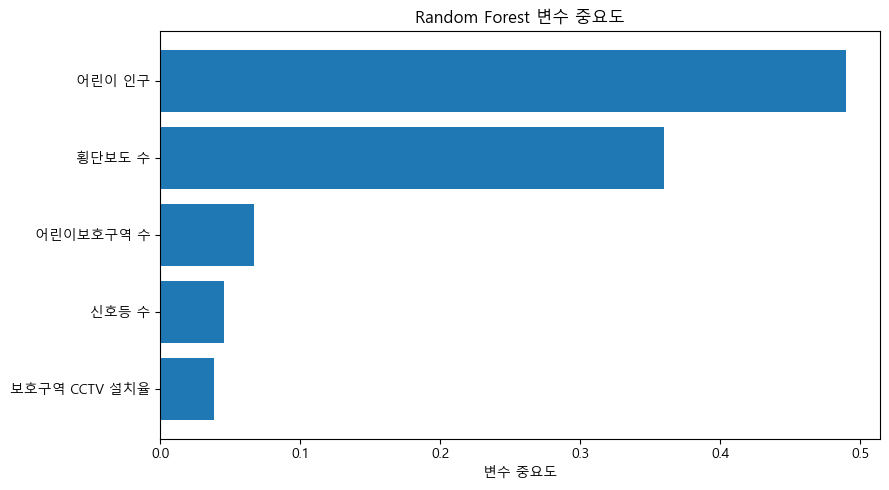

In [10]:
name_map = {
    "child_population_0_12": "어린이 인구",
    "crosswalk_count": "횡단보도 수",
    "traffic_light_count": "신호등 수",
    "schoolzone_count": "어린이보호구역 수",
    "cctv_install_rate": "보호구역 CCTV 설치율"
}

importance_plot = importance_df.copy()
importance_plot["변수"] = importance_plot["변수"].map(name_map)

plt.figure(figsize=(9, 5))

plt.barh(
    importance_plot["변수"],
    importance_plot["중요도"]
)

plt.gca().invert_yaxis()
plt.xlabel("변수 중요도")
plt.title("Random Forest 변수 중요도")

plt.tight_layout()
plt.show()

In [11]:
from sklearn.model_selection import cross_val_predict

# 각 지역을 학습에 사용하지 않은 상태에서 예측값 생성
rf_cv = RandomForestRegressor(
    n_estimators=300,
    max_depth=3,
    min_samples_leaf=2,
    random_state=42
)

y_pred = cross_val_predict(
    rf_cv,
    X_full,
    y,
    cv=cv
)

# 전체 예측 결과 평가
mae = mean_absolute_error(y, y_pred)
rmse = np.sqrt(mean_squared_error(y, y_pred))
r2 = r2_score(y, y_pred)

print("MAE :", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R²  :", round(r2, 3))

MAE : 37.285
RMSE: 56.829
R²  : 0.48


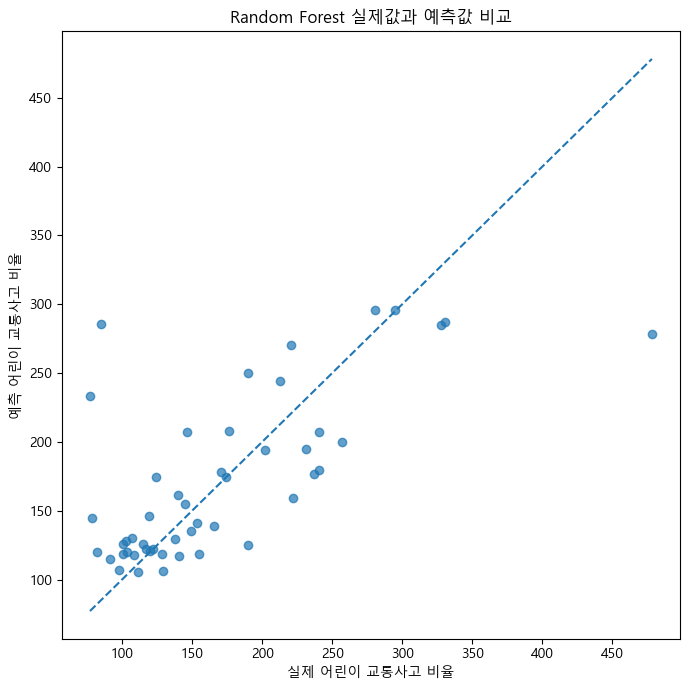

In [12]:
plt.figure(figsize=(7, 7))

plt.scatter(
    y,
    y_pred,
    alpha=0.7
)

min_value = min(y.min(), y_pred.min())
max_value = max(y.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("실제 어린이 교통사고 비율")
plt.ylabel("예측 어린이 교통사고 비율")
plt.title("Random Forest 실제값과 예측값 비교")

plt.tight_layout()
plt.show()

In [13]:
prediction_result = df_model[
    ["sido_sgg_nm"]
].copy()

prediction_result["actual"] = y.values
prediction_result["prediction"] = y_pred
prediction_result["error"] = (
    prediction_result["actual"]
    - prediction_result["prediction"]
).abs()

display(
    prediction_result.sort_values(
        "error",
        ascending=False
    ).head(10)
)

,sido_sgg_nm,actual,prediction,error
12,경기도 의왕시,84.813677,285.458831,200.645154
27,경상북도 영덕군,478.142077,278.614651,199.527425
42,전북특별자치도 진안군,77.120823,233.121602,156.000780
35,세종특별자치시 세종시,78.231537,144.802566,66.571030
39,전라남도 여수시,190.003744,124.893905,65.109839
10,경기도 여주시,222.279659,159.349843,62.929816
16,경기도 포천시,240.756664,179.678096,61.078568
19,경상남도 거창군,146.206201,207.236023,61.029822
23,경상남도 통영시,236.984283,176.530189,60.454094
44,충청남도 서천군,189.814815,249.763459,59.948644


In [14]:
# 지역별 예측 결과 저장
prediction_result.to_csv(
    "../data_processed/model_prediction_49.csv",
    index=False,
    encoding="utf-8-sig"
)

# 최종 Random Forest 모델 저장
import joblib

final_rf.fit(X_full, y)

joblib.dump(
    final_rf,
    "../data_processed/random_forest_model_49.pkl"
)

print("예측 결과 저장 완료")
print("모델 저장 완료")

예측 결과 저장 완료
모델 저장 완료


## 모델링 결과 및 결론

공공데이터가 공통으로 확보된 49개 시군구를 대상으로 어린이 인구,
횡단보도 수, 신호등 수, 어린이보호구역 수, CCTV 설치율을 활용하여
어린이 교통사고 비율을 예측하였다.

Linear Regression, Ridge Regression, Random Forest를 5-Fold 교차검증으로
비교한 결과 Random Forest가 가장 낮은 MAE와 RMSE를 보여 최종 모델로 선정하였다.

Random Forest의 OOF 예측 결과는 MAE 약 37.3, RMSE 약 56.8,
전체 OOF 기준 R² 약 0.48을 보였다.
다만 Fold별 R² 평균은 약 0.03으로 낮아 지역 구성에 따라 모델 성능의
변동이 큰 것으로 나타났다.

또한 어린이 인구만 사용한 모델과 교통안전시설을 함께 사용한 모델의
성능 차이가 크지 않아, 현재 확보한 교통안전시설 변수만으로는
사고 위험도 예측 성능을 크게 높이기 어려운 것으로 나타났다.

변수 중요도에서는 어린이 인구와 횡단보도 수가 상대적으로 높게 나타났으나,
이는 인과관계를 의미하지 않으며 모델이 예측 과정에서 해당 변수를
상대적으로 많이 사용했다는 의미이다.

일부 지역에서는 실제값과 예측값의 차이가 크게 나타났으며,
특히 사고비율이 매우 높거나 낮은 지역에 대한 예측 성능이 부족하였다.

향후에는 과거 연도별 사고 추세, 교통량, 도로 환경, 학교 및 통학 관련 데이터 등을
추가하여 지역별 어린이 교통사고 위험 예측 성능을 개선할 필요가 있다.